# Mode Identification with Multimodal Source Distributions

In [19]:
import time

import torch 
from torch import nn, Tensor
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import numpy as np

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

In [ ]:
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 150,
    'font.size': 13,
    'axes.titlesize': 15,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 17,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'lines.linewidth': 2.0,
})

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

### Load MNIST dataset

In [ ]:


# Normalize pixel values from [0, 1] to [-1, 1] so the data matches a standard
# Gaussian source for flow matching.
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.MNIST(root='../../data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='../../data', train=False, download=True, transform=transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f'Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}')
images, labels = next(iter(train_loader))
print(f'Batch images shape: {images.shape}, labels shape: {labels.shape}')

Train samples: 60000, Test samples: 10000
Batch images shape: torch.Size([128, 1, 28, 28]), labels shape: torch.Size([128])


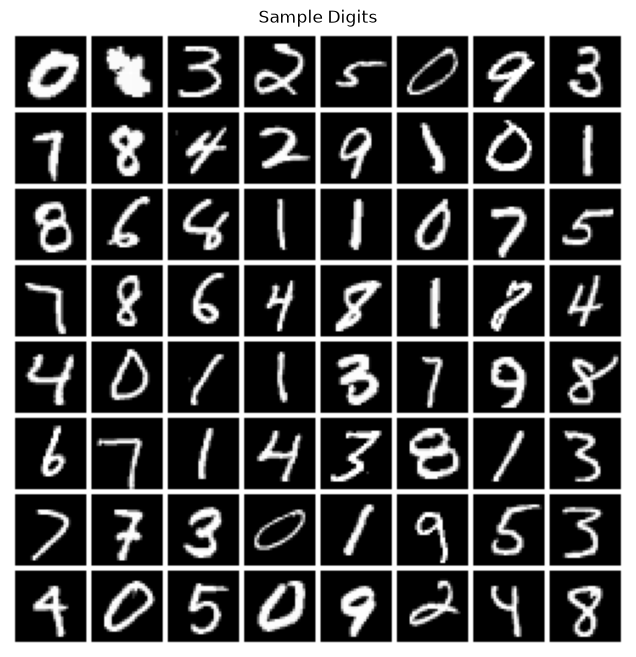

In [5]:
## Display some sample digits

def show_samples(images: Tensor, nrow: int=8, ax=None):
    # images = (images + 1) / 2  # denormalize
    images = images.clamp(0, 1)
    grid = make_grid(images[:nrow**2], nrow, padding=2, pad_value=1)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    ax.set_aspect('equal')
    ax.set_title('Sample Digits')
    ax.imshow(grid.permute(1, 2, 0).cpu())
    ax.axis('off')
    return ax

show_samples(images);

In [9]:
class Flow(nn.Module):

    def __init__(self, dim: int=28*28, h: int=128):
        super().__init__()
        self.dim = dim
        self.h = h

        self.net = nn.Sequential(
            nn.Linear(dim+1, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, h),
            nn.ReLU(),
            nn.Linear(h, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, dim),
        )
    def forward(self, x, t):
        x_t = torch.cat([x, t], dim=1)
        return self.net(x_t)

    def step(self, x_t: Tensor, t_start: float, t_end: float):
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t + dt * self(x_t + self(x_t, t=t_start)*dt/2, t=(t_start + t_end)/2)



In [10]:
from scipy.optimize import linear_sum_assignment
from scipy.spatial import distance

### Will it identify modes?

We replace the single Gaussian source with a mixture of 10 random modes $\mu_0,\ldots,\mu_9 \in \mathbb{R}^{784}$. Each training sample is drawn from a random mode and OT coupling pairs it to the nearest target. The question: does the unconditional flow model learn to generate coherent digits when started from each mode, without ever seeing explicit class labels?

In [16]:
mus = torch.randn(10, 784).to(device)*0.2 + 0.5

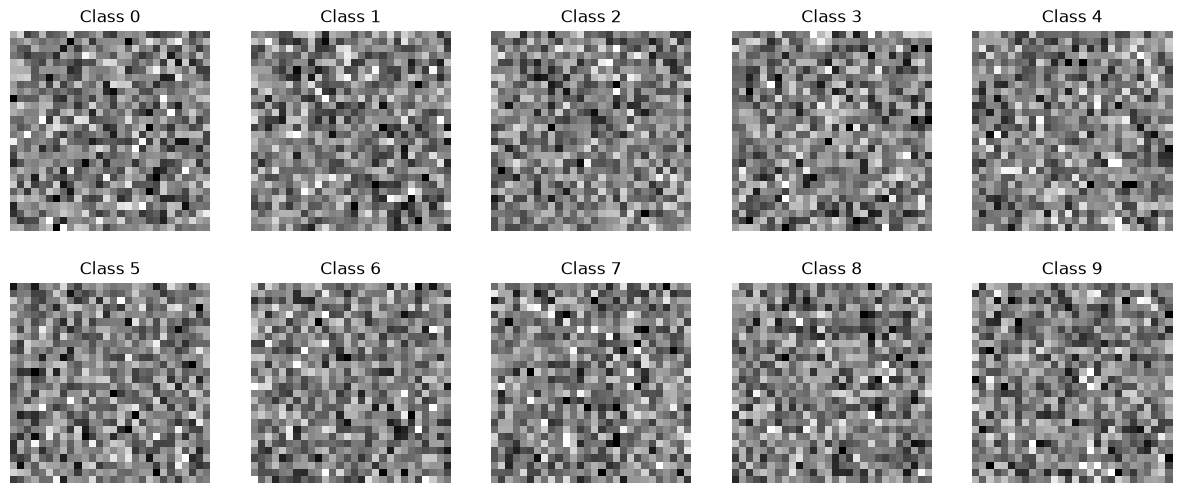

In [19]:
fig, axs = plt.subplots(2, 5, figsize=(15, 6))
for i in range(10):
    axs[i//5, i%5] = show_samples(mus[i].view(-1, 1, 28, 28), nrow=1, ax=axs[i//5, i%5])
    axs[i//5, i%5].set_title(f'Class {i}')

plt.show()

In [ ]:
N_EPOCHS = 50

flow = Flow(h=256).to(device)
opt = torch.optim.Adam(flow.parameters(), lr=1e-3)
losses = []

for e in range(N_EPOCHS):
    avg_loss = 0.0
    for i, (x, _) in enumerate(train_loader):
        x_1 = x.view(-1, 784).to(device)

        t = torch.rand(x.shape[0], 1, device=x_1.device)
        modes = torch.randint(0, 10, (x_1.shape[0],), device=x_1.device)

        x_0 = torch.randn_like(x_1)*0.2 + mus[modes]
        cost = distance.cdist(x_0.cpu().numpy(), x_1.cpu().numpy())
        row_ind, col_ind = linear_sum_assignment(cost)
        dx_t = x_1[col_ind] - x_0[row_ind]
        x_t = (1-t)*x_0[row_ind] + t * x_1[col_ind]
        flow_pred = flow(x_t, t)

        loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
        loss.backward()
        opt.step()
        opt.zero_grad()
        avg_loss += loss.item()
    avg_loss /= len(train_loader)
    losses.append(avg_loss)
    print(f'\r[{100*(e+1)/N_EPOCHS:.0f}%] Epoch {e+1}/{N_EPOCHS}  loss: {avg_loss:.4f}', end='', flush=True)

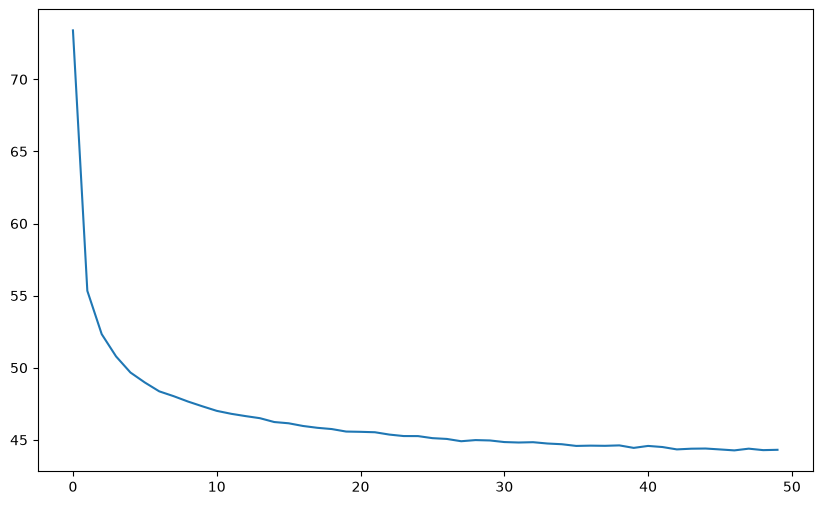

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(losses)
plt.show();

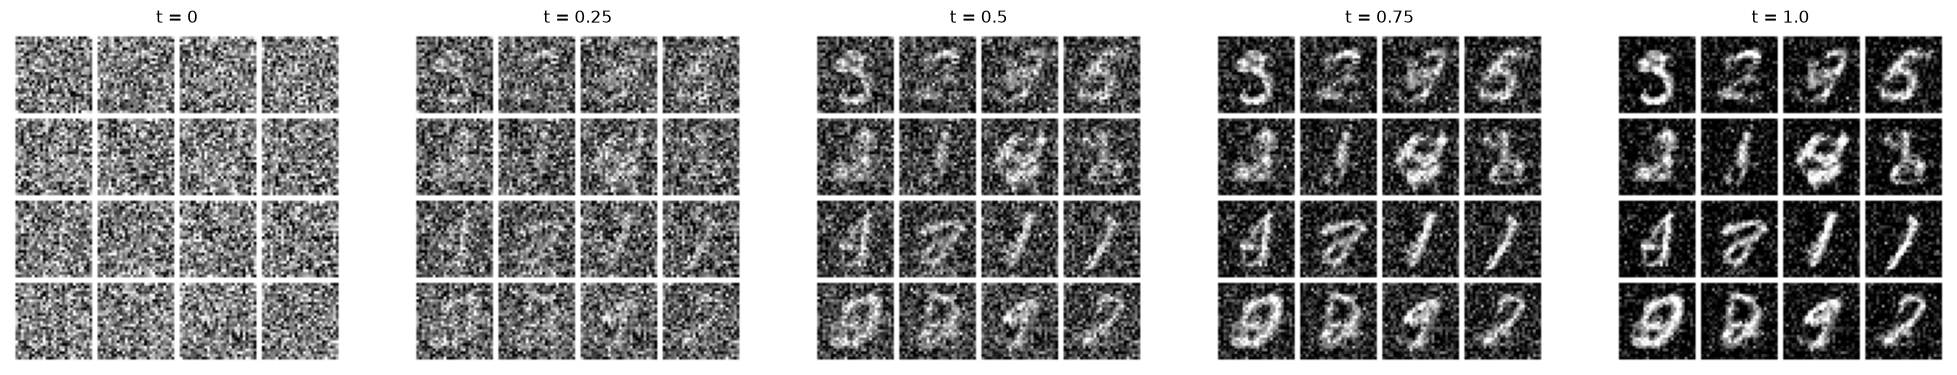

In [22]:


modes = torch.randint(0, 10, (16,), device=device)

x = torch.randn(16, 784).to(device)*0.2 + mus[modes]
n_steps = 100
time_steps = torch.linspace(0, 1.0, n_steps + 1)

# Precompute the point cloud at every time step.
states = [x]
with torch.no_grad():
    for i in range(n_steps):
        x = flow.step(x_t=x, t_start=time_steps[i].to(device), t_end=time_steps[i + 1].to(device))
        states.append(x)
states = [s.detach() for s in states]

fig, ax = plt.subplots(1, 5, figsize=(25, 10))
ax = ax.reshape(-1)
ax[0] = show_samples(states[0].view(-1, 1, 28, 28), nrow=4, ax=ax[0])
ax[0].set_title('t = 0')
ax[1] = show_samples(states[25].view(-1, 1, 28, 28), nrow=4, ax=ax[1])
ax[1].set_title('t = 0.25')
ax[2] = show_samples(states[50].view(-1, 1, 28, 28), nrow=4, ax=ax[2])
ax[2].set_title('t = 0.5')
ax[3] = show_samples(states[75].view(-1, 1, 28, 28), nrow=4, ax=ax[3])
ax[3].set_title('t = 0.75')
ax[4] = show_samples(states[-1].view(-1, 1, 28, 28), nrow=4, ax=ax[4])
ax[4].set_title('t = 1.0')

plt.show()

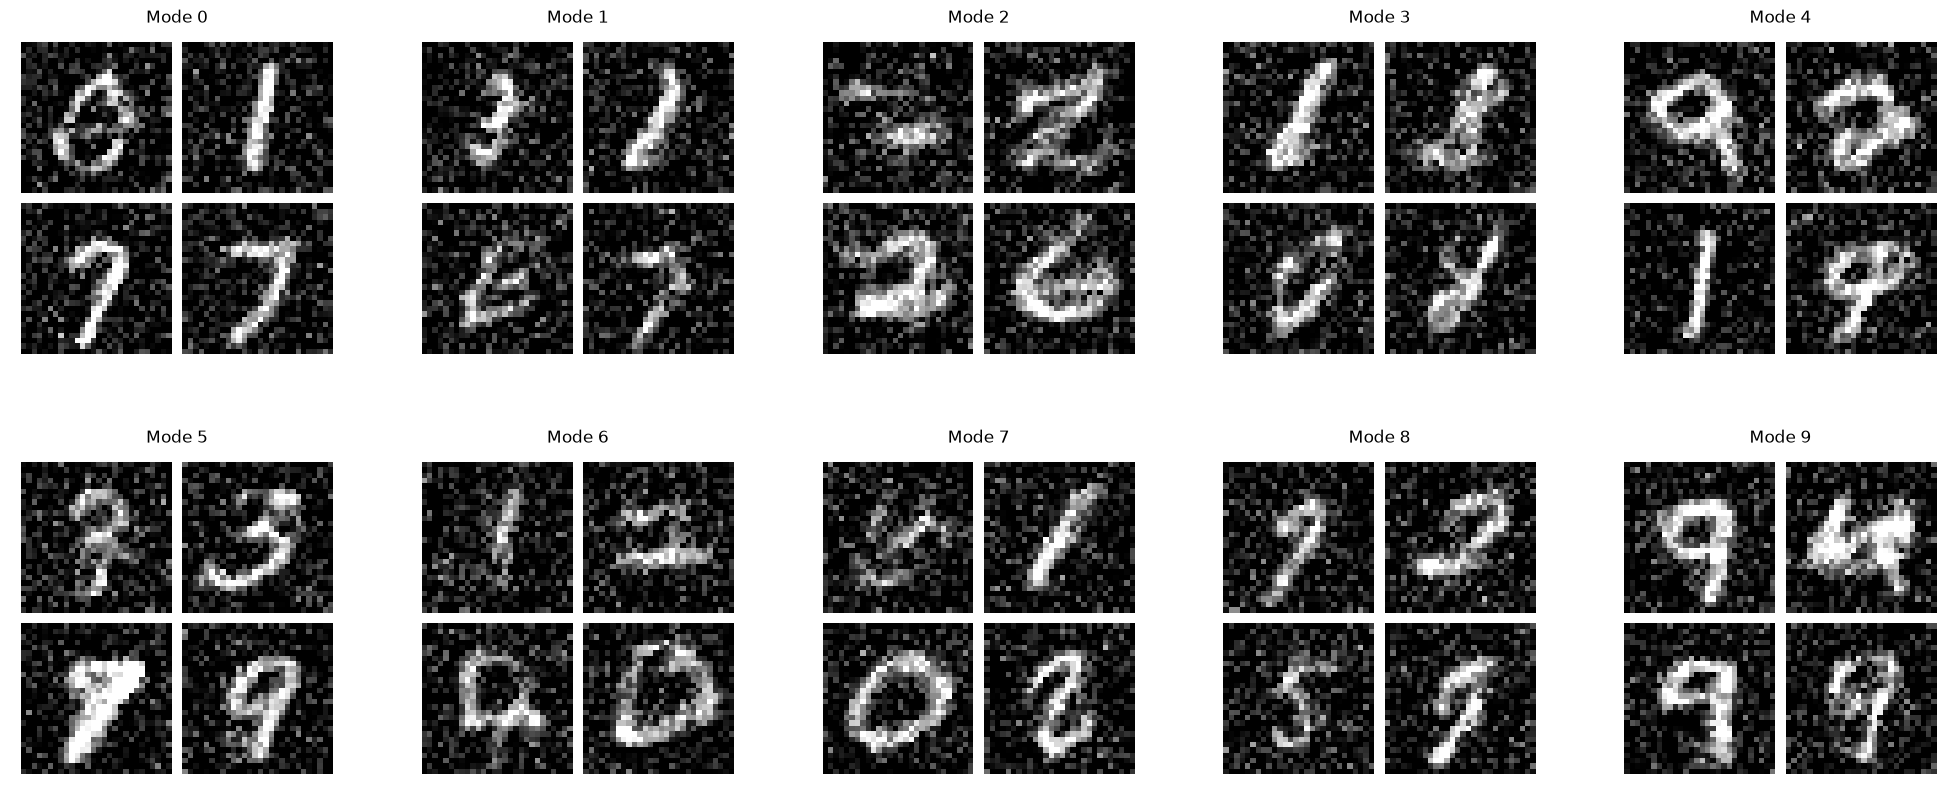

In [24]:
fig, ax = plt.subplots(2, 5, figsize=(25, 10))
ax = ax.reshape(-1)
for i in range(10):
    with torch.no_grad():
        x = torch.randn(4, 784).to(device)*0.2 + mus[i]
        for j in range(n_steps):
            x = flow.step(x_t=x, t_start=time_steps[j].to(device), t_end=time_steps[j + 1].to(device))
        ax[i] = show_samples(x.view(-1, 1, 28, 28), nrow=2, ax=ax[i])
        ax[i].set_title(f'Mode {i}')
plt.show()
        